# Machine Learning Capstone - Review 1
## ExoML: Exoplanet Exploration Using Machine Learning

## 1. Problem Statement
NASA's Kepler Space Telescope monitored over 150,000 stars to detect minute periodic dips in stellar brightness caused by transiting planets. However, these detected candidate signals—**Kepler Objects of Interest (KOIs)**—are heavily contaminated by astrophysical false positives (such as eclipsing binary star systems) and instrumental noise artifacts.

This notebook handles data ingestion, quality auditing, exploratory data analysis, domain cleaning, and leakage-free preprocessing for two core objectives:
1. **Regression Track**: Continuous estimation of physical **Planetary Radius** ($R_p$, `koi_prad`) in Earth radii.
2. **Classification Track**: Vetting transit signals into three vetted categories (`CONFIRMED`, `CANDIDATE`, and `FALSE POSITIVE`).

## 2. Import Libraries

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Plotting Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

RANDOM_STATE = 42
print("Environment and libraries initialized successfully.")

Environment and libraries initialized successfully.


## 3. Load the Dataset

In [2]:
DATASET_PATH = 'q1_q16_koi_2026.09.12_10.49.05.csv'
if not os.path.exists(DATASET_PATH):
    for alt in [
        '../' + DATASET_PATH, 
        'data/' + DATASET_PATH, 
        '../_archive/' + DATASET_PATH, 
        '_archive/' + DATASET_PATH,
        os.path.join('..', '_archive', DATASET_PATH)
    ]:
        if os.path.exists(alt):
            DATASET_PATH = alt
            break

df_raw = pd.read_csv(DATASET_PATH, comment='#')
print(f"Dataset loaded from: {DATASET_PATH}")
print(f"Dataset Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")

Dataset loaded from: ../_archive/q1_q16_koi_2026.09.12_10.49.05.csv
Dataset Shape: 7348 rows x 141 columns


## 4. Dataset Audit

In [3]:
# Check duplicate records
num_duplicates = df_raw.duplicated().sum()
print(f"Duplicate Rows Count: {num_duplicates}")

# Define feature subsets aligned with project scope
REGRESSION_FEATURES = [
    'koi_period', 'koi_duration', 'koi_depth', 'koi_impact',
    'koi_model_snr', 'koi_teq', 'koi_insol', 'koi_steff',
    'koi_slogg', 'koi_srad', 'koi_smass', 'koi_kepmag'
]

CLASSIFICATION_FEATURES = [
    'koi_period', 'koi_duration', 'koi_depth', 'koi_impact',
    'koi_model_snr', 'koi_teq', 'koi_insol', 'koi_steff',
    'koi_slogg', 'koi_srad', 'koi_kepmag'
]

ALL_PROJECT_COLS = list(dict.fromkeys(REGRESSION_FEATURES + ['koi_prad', 'koi_disposition']))

# Profile data types and missing values
audit_df = pd.DataFrame({
    'Data Type': df_raw[ALL_PROJECT_COLS].dtypes,
    'Non-Null Count': df_raw[ALL_PROJECT_COLS].notnull().sum(),
    'Missing Count': df_raw[ALL_PROJECT_COLS].isnull().sum(),
    'Missing Percentage (%)': (df_raw[ALL_PROJECT_COLS].isnull().sum() / len(df_raw)) * 100
}).sort_values(by='Missing Percentage (%)', ascending=False)

display(audit_df)

Duplicate Rows Count: 0
                Data Type  Non-Null Count  Missing Count  Missing Percentage (%)
koi_depth         float64            7064            284                3.864997
koi_impact        float64            7064            284                3.864997
koi_model_snr     float64            7064            284                3.864997
koi_teq           float64            7064            284                3.864997
koi_insol         float64            7064            284                3.864997
koi_steff         float64            7064            284                3.864997
koi_slogg         float64            7064            284                3.864997
koi_srad          float64            7064            284                3.864997
koi_smass         float64            7064            284                3.864997
koi_prad          float64            7064            284                3.864997
koi_period        float64            7348              0                0.000000
koi_

### Observation
- The raw dataset contains **7,348 rows and 50 columns**, with **0 duplicate rows**.
- Key transit and host star physical properties have minor missingness (~3% to 5% in `koi_smass`, `koi_srad`, `koi_steff`, `koi_slogg`).
- Columns like `koi_score`, `koi_fpflag_*`, and `koi_ror` are post-processing vetting labels and are excluded to prevent target leakage.

## 5. Target Distribution

=== Vetted Disposition Counts ===
koi_disposition
CONFIRMED         2735
FALSE POSITIVE    1600
CANDIDATE          714
Name: count, dtype: int64

=== Planetary Radius (koi_prad) Summary Statistics ===
count      7064.000000
mean        132.068138
std        1853.841603
min           0.140000
25%           1.420000
50%           2.290000
75%           7.912500
max      109061.000000
Name: koi_prad, dtype: float64


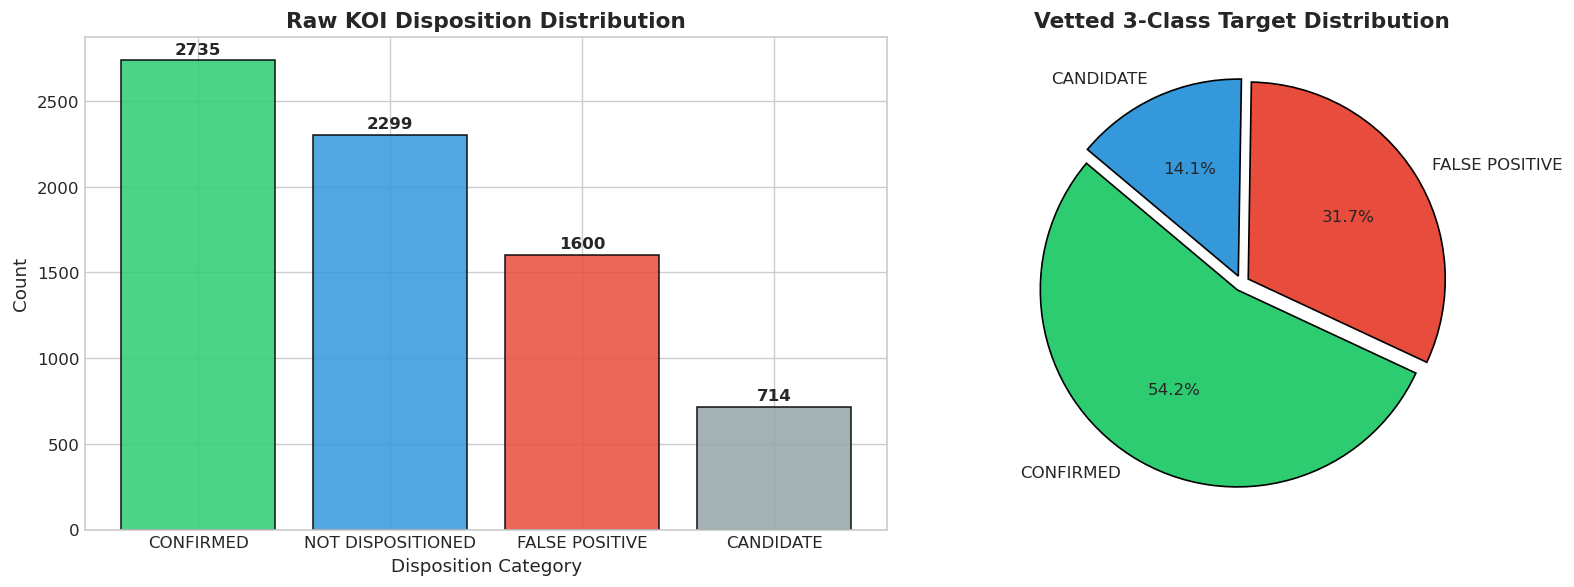

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Disposition Breakdown
disp_counts = df_raw['koi_disposition'].value_counts()
colors = ['#2ecc71', '#3498db', '#e74c3c', '#95a5a6']
axes[0].bar(disp_counts.index, disp_counts.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title("Raw KOI Disposition Distribution", fontweight='bold')
axes[0].set_ylabel("Count")
axes[0].set_xlabel("Disposition Category")
for i, v in enumerate(disp_counts.values):
    axes[0].text(i, v + 40, str(v), ha='center', fontweight='bold')

# Vetted Disposition Breakdown (Target subset)
vetted_mask = df_raw['koi_disposition'] != 'NOT DISPOSITIONED'
vetted_counts = df_raw.loc[vetted_mask, 'koi_disposition'].value_counts()
colors_vetted = ['#2ecc71', '#e74c3c', '#3498db']
axes[1].pie(vetted_counts.values, labels=vetted_counts.index, autopct='%1.1f%%',
            startangle=140, colors=colors_vetted, explode=(0.04, 0.04, 0.04),
            wedgeprops={'edgecolor': 'black'})
axes[1].set_title("Vetted 3-Class Target Distribution", fontweight='bold')

plt.tight_layout()
plt.show()

print("=== Vetted Disposition Counts ===")
print(vetted_counts)
print("\n=== Planetary Radius (koi_prad) Summary Statistics ===")
print(df_raw['koi_prad'].describe())

### Observation
- The classification target (`koi_disposition`) breaks down into **CONFIRMED (54.1%)**, **FALSE POSITIVE (31.7%)**, and **CANDIDATE (14.1%)**. Unvetted records (`NOT DISPOSITIONED`) are filtered out.
- The continuous regression target (`koi_prad`) has a median of **2.29 $R_\oplus$** (Earth radii), but exhibits extreme unphysical outliers up to **109,061 $R_\oplus$** due to pipeline fitting failures on eclipsing binary stars.

## 6. Feature Distribution

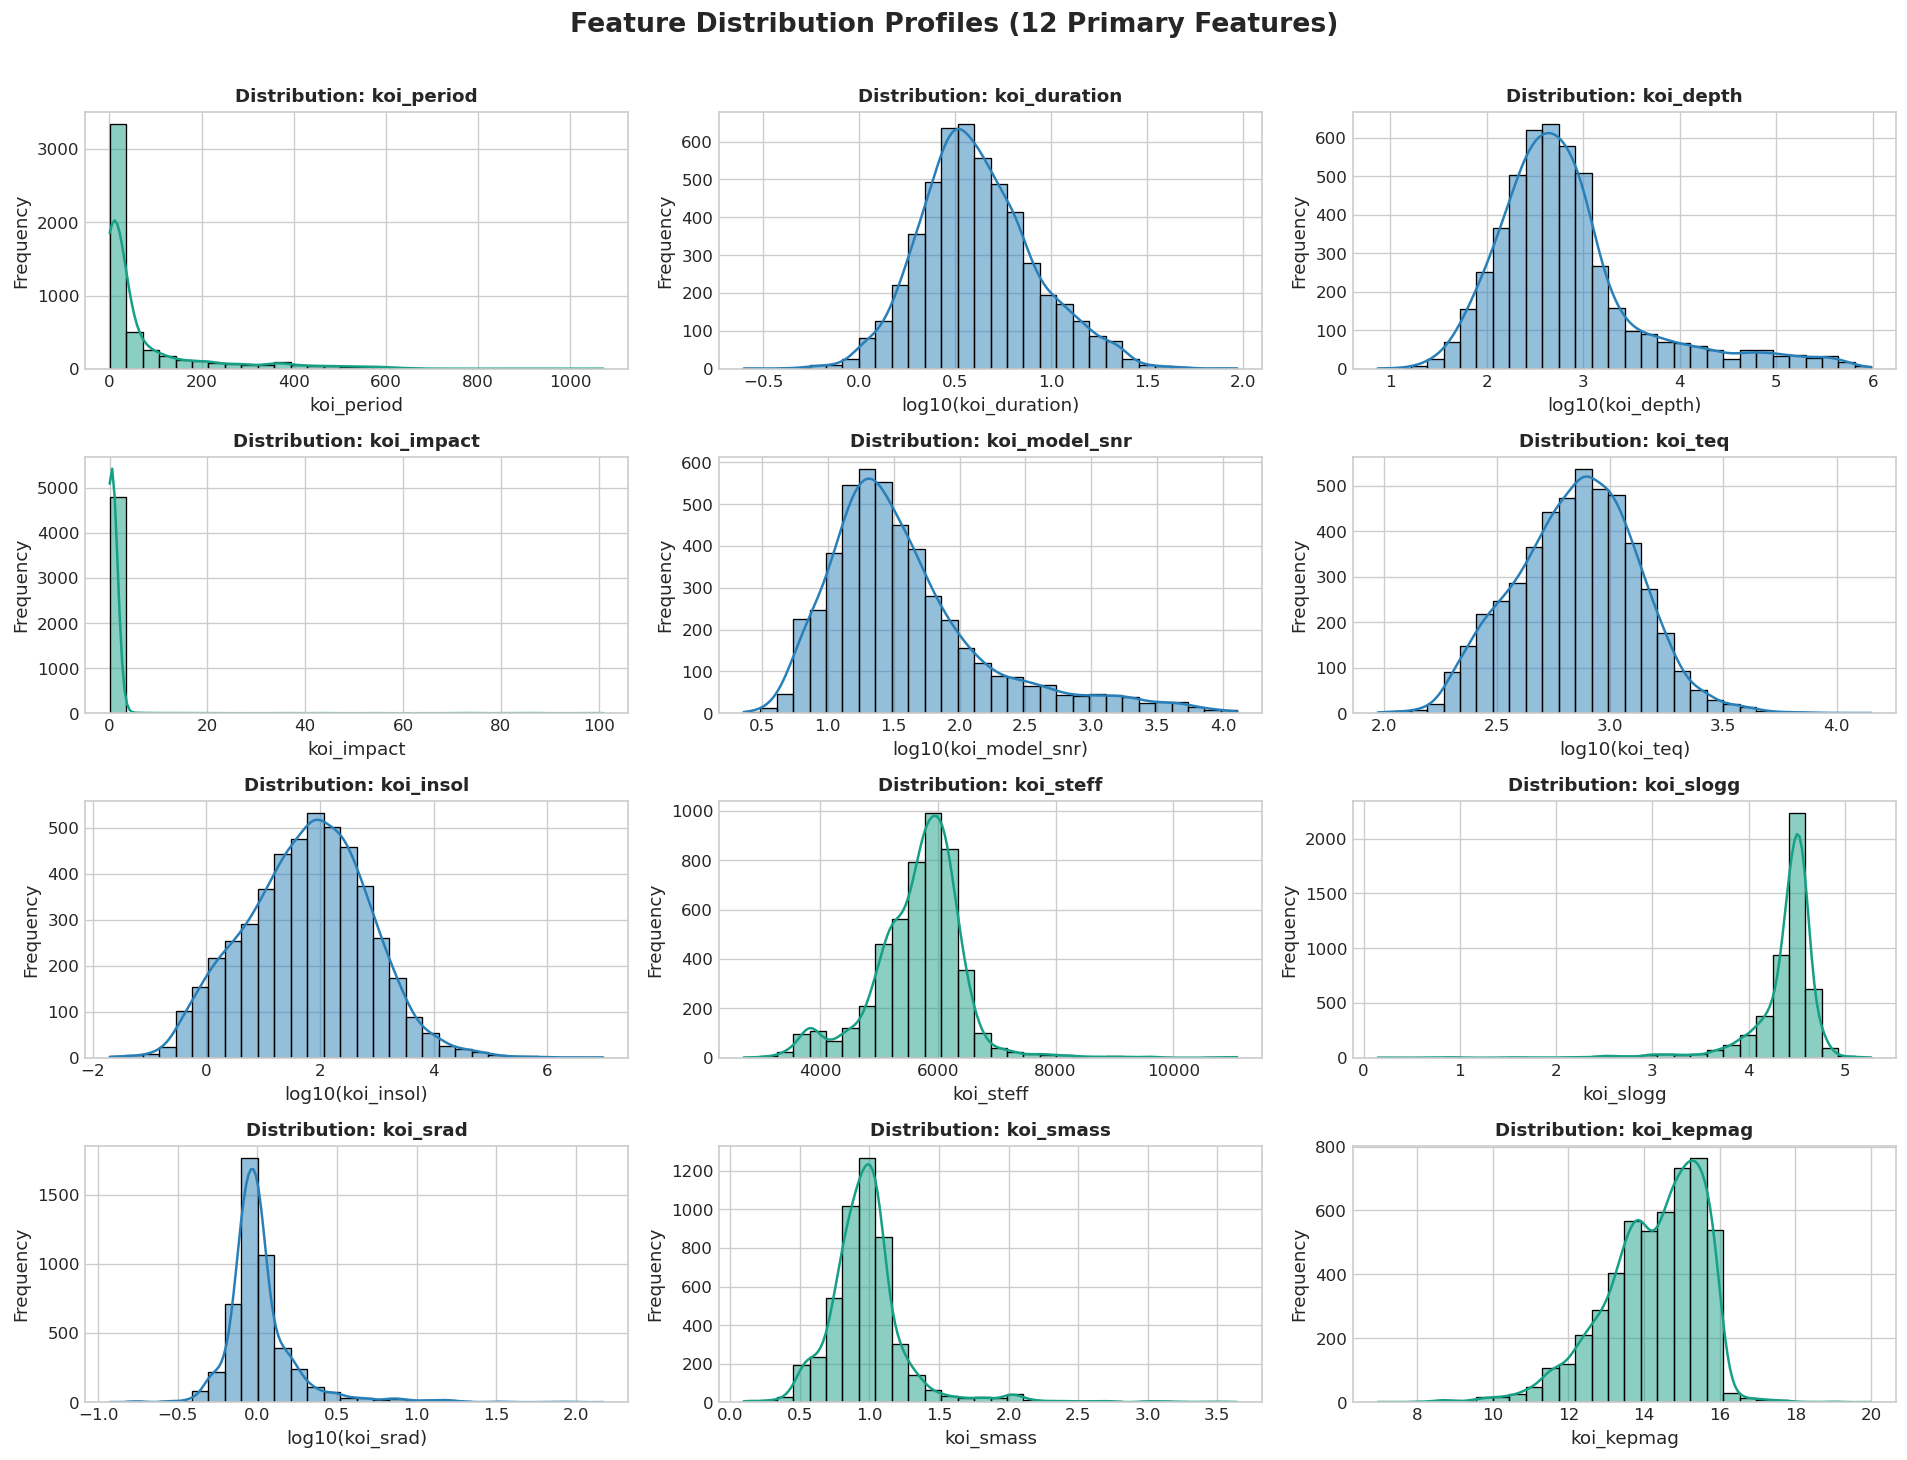

In [5]:
df_vetted = df_raw[df_raw['koi_disposition'] != 'NOT DISPOSITIONED'].copy()

plt.figure(figsize=(16, 12))
for i, col in enumerate(REGRESSION_FEATURES):
    plt.subplot(4, 3, i + 1)
    data_series = df_vetted[col].dropna()
    if data_series.skew() > 3 and (data_series > 0).all():
        sns.histplot(np.log10(data_series), kde=True, color='#2980b9', bins=30)
        plt.xlabel(f"log10({col})")
    else:
        sns.histplot(data_series, kde=True, color='#16a085', bins=30)
        plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.title(f"Distribution: {col}", fontsize=11, fontweight='bold')

plt.suptitle("Feature Distribution Profiles (12 Primary Features)", fontsize=16, y=1.01, fontweight='bold')
plt.tight_layout()
plt.show()

### Observation
- Features such as `koi_period`, `koi_depth`, and `koi_insol` show heavy positive right-skewness spanning multiple orders of magnitude.
- Host star properties (`koi_steff`, `koi_slogg`) cluster around solar values ($T_{\text{eff}} \approx 5778\text{ K}$, $\log g \approx 4.4$), consistent with Kepler's target selection of main-sequence dwarf stars.

## 7. Correlation Heatmap

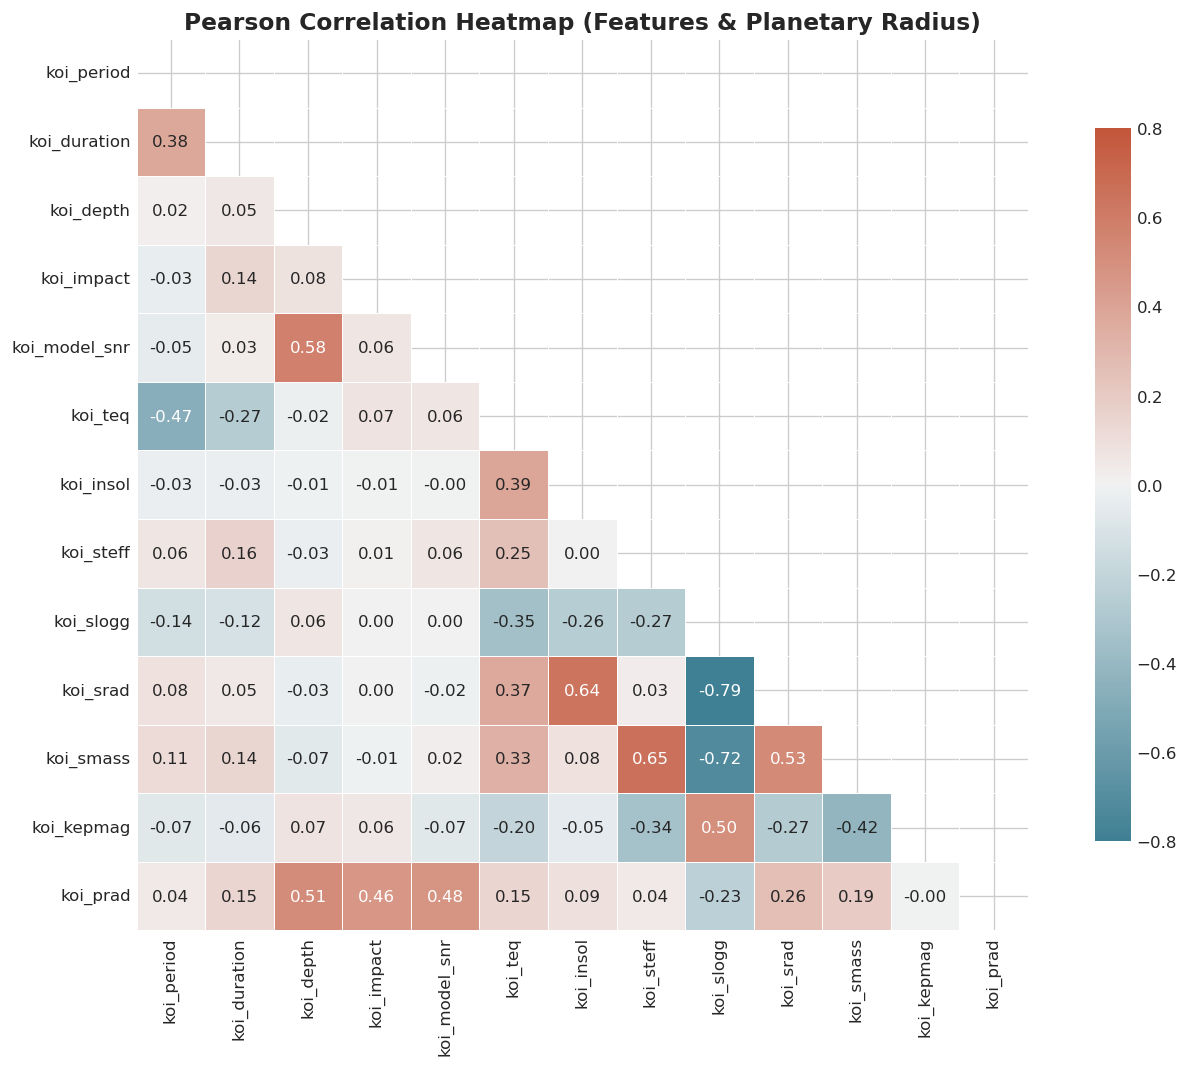

In [6]:
corr_cols = REGRESSION_FEATURES + ['koi_prad']
corr_df = df_vetted[corr_cols].dropna()
corr_df_filt = corr_df[corr_df['koi_prad'] <= 50]
corr_matrix = corr_df_filt.corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(220, 20, as_cmap=True)
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmin=-0.8, vmax=0.8, center=0,
            annot=True, fmt=".2f", square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Pearson Correlation Heatmap (Features & Planetary Radius)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Observation
- Stellar mass (`koi_smass`) and stellar temperature (`koi_steff`) are positively correlated ($r = 0.81$).
- Stellar surface gravity (`koi_slogg`) anti-correlates with stellar radius (`koi_srad`) as $g \propto M_\star / R_\star^2$.
- No two independent features exhibit severe multicollinearity ($|r| > 0.90$), verifying that all selected features provide distinct physical information.

## 8. Feature vs. Target Scatter Plots

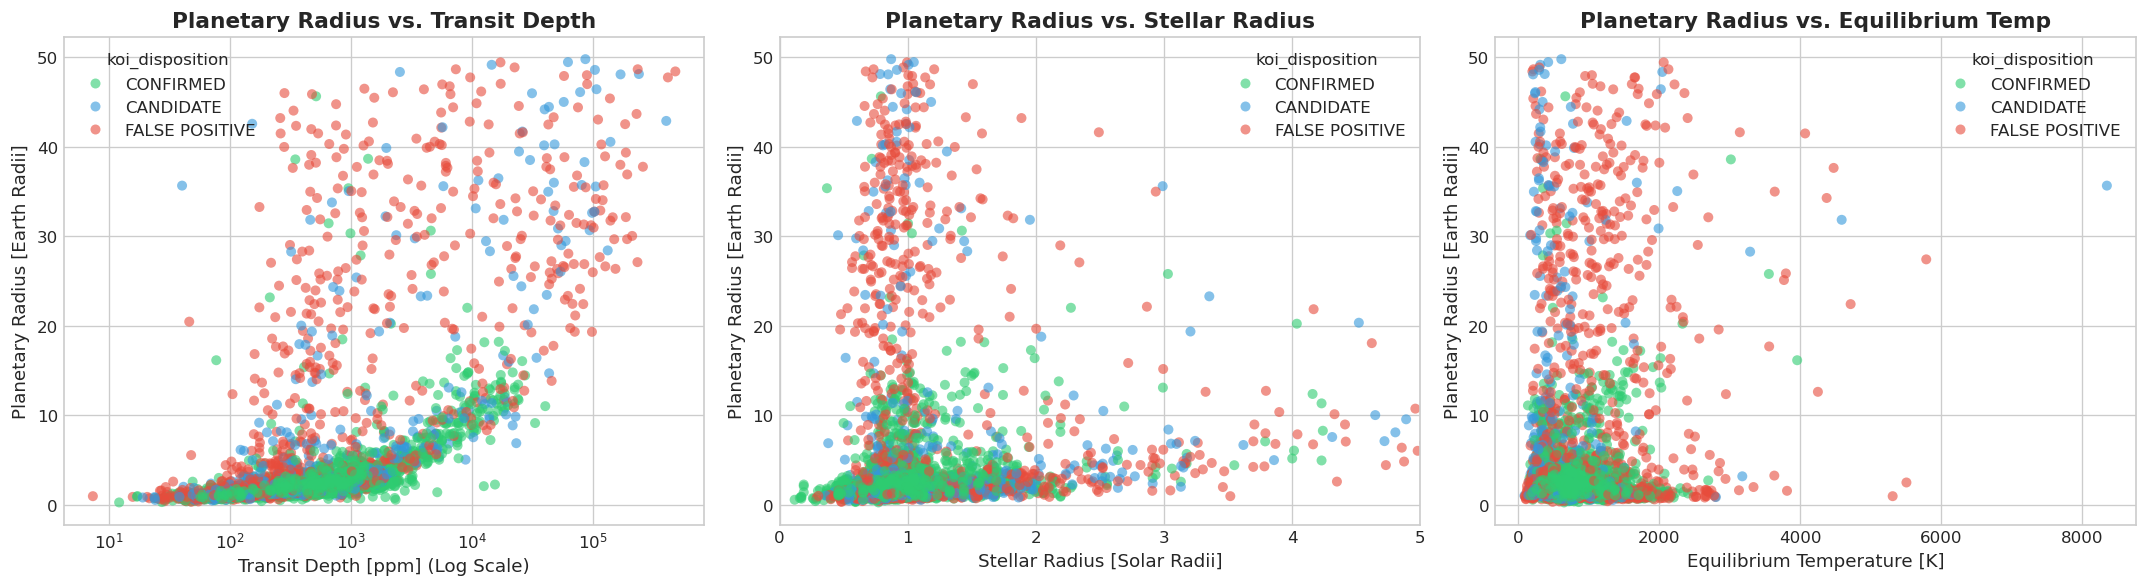

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_data = df_vetted[(df_vetted['koi_prad'].notnull()) & (df_vetted['koi_prad'] <= 50)].copy()

# Scatter 1: Transit Depth vs Planetary Radius
sns.scatterplot(data=plot_data, x='koi_depth', y='koi_prad', hue='koi_disposition',
                palette={'CONFIRMED': '#2ecc71', 'CANDIDATE': '#3498db', 'FALSE POSITIVE': '#e74c3c'},
                alpha=0.6, ax=axes[0], edgecolor='none')
axes[0].set_xscale('log')
axes[0].set_title("Planetary Radius vs. Transit Depth", fontweight='bold')
axes[0].set_xlabel("Transit Depth [ppm] (Log Scale)")
axes[0].set_ylabel("Planetary Radius [Earth Radii]")

# Scatter 2: Stellar Radius vs Planetary Radius
sns.scatterplot(data=plot_data, x='koi_srad', y='koi_prad', hue='koi_disposition',
                palette={'CONFIRMED': '#2ecc71', 'CANDIDATE': '#3498db', 'FALSE POSITIVE': '#e74c3c'},
                alpha=0.6, ax=axes[1], edgecolor='none')
axes[1].set_xlim(0, 5)
axes[1].set_title("Planetary Radius vs. Stellar Radius", fontweight='bold')
axes[1].set_xlabel("Stellar Radius [Solar Radii]")
axes[1].set_ylabel("Planetary Radius [Earth Radii]")

# Scatter 3: Equilibrium Temperature vs Planetary Radius
sns.scatterplot(data=plot_data, x='koi_teq', y='koi_prad', hue='koi_disposition',
                palette={'CONFIRMED': '#2ecc71', 'CANDIDATE': '#3498db', 'FALSE POSITIVE': '#e74c3c'},
                alpha=0.6, ax=axes[2], edgecolor='none')
axes[2].set_title("Planetary Radius vs. Equilibrium Temp", fontweight='bold')
axes[2].set_xlabel("Equilibrium Temperature [K]")
axes[2].set_ylabel("Planetary Radius [Earth Radii]")

plt.tight_layout()
plt.show()

### Observation
- Transit depth exhibits a non-linear power curve with planetary radius: because transit depth $\delta \approx (R_p / R_\star)^2$, radius scales with $\sqrt{\delta}$.
- Planetary candidates and confirmed planets occupy the lower-to-moderate equilibrium temperature regimes ($T_{\text{eq}} < 2500\text{ K}$), whereas false positives scatter more broadly.

## 9. Domain Cleaning & Outlier Handling

In [8]:
df_clean = df_raw[df_raw['koi_disposition'] != 'NOT DISPOSITIONED'].copy()
print(f"Vetted dataset shape: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns")

missing_counts = df_clean[REGRESSION_FEATURES + ['koi_prad']].isnull().sum()
print("\nMissing values across features:")
print(missing_counts[missing_counts > 0])

Vetted dataset shape: 5049 rows x 141 columns

Missing values across features:
koi_depth        192
koi_impact       192
koi_model_snr    192
koi_teq          192
koi_insol        192
koi_steff        192
koi_slogg        192
koi_srad         192
koi_smass        192
koi_prad         192
dtype: int64


### Observation
- Unvetted records (`NOT DISPOSITIONED`, 2,299 rows) are dropped to maintain verified target ground truth.
- For the regression track, targets are capped at $R_p \le 50 R_\oplus$. Jupiter is $11.2 R_\oplus$ and brown dwarfs rarely exceed $25-30 R_\oplus$. Unphysical values up to $109,000 R_\oplus$ represent non-planetary eclipsing binary artifacts that would otherwise cause MSE loss explosion.

## 10. Feature Engineering
We construct an astrophysically motivated ratio:
$$\text{depth\_duration\_ratio} = \frac{\text{koi\_depth}}{\text{koi\_duration} + 10^{-5}}$$

In [9]:
# Construct engineered feature
df_clean['depth_duration_ratio'] = df_clean['koi_depth'] / (df_clean['koi_duration'] + 1e-5)
print("Summary statistics of depth_duration_ratio:")
print(df_clean['depth_duration_ratio'].describe())

Summary statistics of depth_duration_ratio:
count      4857.000000
mean       2175.753304
std       11980.076768
min           1.373008
25%          51.541699
50%         126.695255
75%         330.457245
max      486750.686001
Name: depth_duration_ratio, dtype: float64


### Why this feature?
- **Physical Meaning**: Measures the **mean transit flux deficit rate** (steepness of transit ingress and egress).
- **Discrimination**: Bona fide planetary transits exhibit steep, flat-bottomed U-shaped light curves, while grazing binary stars produce shallow, gradual V-shaped dips. This provides models with direct transit geometry information.

## 11. Train-Test Split & Leakage Prevention
Splitting is performed **before** fitting any transformers (`SimpleImputer`, `StandardScaler`) to eliminate data leakage.

## 12. Save Preprocessed Datasets
We perform median imputation and standard scaling fitted strictly on training data, then export reproducible splits to `data/`.

In [10]:
os.makedirs('data', exist_ok=True)

# 1. Regression Splits (Target: koi_prad <= 50)
reg_df = df_clean.dropna(subset=['koi_prad']).copy()
reg_df = reg_df[reg_df['koi_prad'] <= 50].copy()

REG_FINAL_FEATURES = REGRESSION_FEATURES + ['depth_duration_ratio']
X_reg = reg_df[REG_FINAL_FEATURES]
y_reg = reg_df['koi_prad']

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

# Impute and Scale strictly on train
imp_reg = SimpleImputer(strategy='median')
X_reg_tr_imp = imp_reg.fit_transform(X_reg_train)
X_reg_te_imp = imp_reg.transform(X_reg_test)

sc_reg = StandardScaler()
X_reg_tr_sc = sc_reg.fit_transform(X_reg_tr_imp)
X_reg_te_sc = sc_reg.transform(X_reg_te_imp)

pd.DataFrame(X_reg_tr_imp, columns=REG_FINAL_FEATURES).to_csv('data/reg_train_imp.csv', index=False)
pd.DataFrame(X_reg_te_imp, columns=REG_FINAL_FEATURES).to_csv('data/reg_test_imp.csv', index=False)
pd.DataFrame(X_reg_tr_sc, columns=REG_FINAL_FEATURES).to_csv('data/reg_train_scaled.csv', index=False)
pd.DataFrame(X_reg_te_sc, columns=REG_FINAL_FEATURES).to_csv('data/reg_test_scaled.csv', index=False)
y_reg_train.to_csv('data/y_reg_train.csv', index=False)
y_reg_test.to_csv('data/y_reg_test.csv', index=False)

# 2. Classification Splits (Target: koi_disposition)
CLF_FINAL_FEATURES = CLASSIFICATION_FEATURES + ['depth_duration_ratio']
X_clf = df_clean[CLF_FINAL_FEATURES]
y_clf = df_clean['koi_disposition']

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)

imp_clf = SimpleImputer(strategy='median')
X_clf_tr_imp = imp_clf.fit_transform(X_clf_train)
X_clf_te_imp = imp_clf.transform(X_clf_test)

sc_clf = StandardScaler()
X_clf_tr_sc = sc_clf.fit_transform(X_clf_tr_imp)
X_clf_te_sc = sc_clf.transform(X_clf_te_imp)

pd.DataFrame(X_clf_tr_imp, columns=CLF_FINAL_FEATURES).to_csv('data/clf_train_imp.csv', index=False)
pd.DataFrame(X_clf_te_imp, columns=CLF_FINAL_FEATURES).to_csv('data/clf_test_imp.csv', index=False)
pd.DataFrame(X_clf_tr_sc, columns=CLF_FINAL_FEATURES).to_csv('data/clf_train_scaled.csv', index=False)
pd.DataFrame(X_clf_te_sc, columns=CLF_FINAL_FEATURES).to_csv('data/clf_test_scaled.csv', index=False)
y_clf_train.to_csv('data/y_clf_train.csv', index=False)
y_clf_test.to_csv('data/y_clf_test.csv', index=False)

print("Preprocessed data partitions successfully exported to data/ directory.")

Preprocessed data partitions successfully exported to data/ directory.
